# Substitution of the isotropic hardening slot

This notebook illustrates the substitution strategy of hybridization. The slot considered is the
isotropic hardening law $p \mapsto \sigma_y(p)$ of an elastoplastic model, where $p$ is the
cumulated plastic strain and $\sigma_y$ the current yield stress; the rest of the model is
unchanged. Four implementations of this slot, from a closed-form phenomenological law to a
generic neural approximator, are calibrated on the same data, with the same loss and the same
optimizer:

1. a **Voce** law (3 parameters);
2. a **sum of saturating exponentials** with fixed rates, whose amplitudes are penalized by an
   $\ell^1$ norm so that a sparse subset of terms is selected;
3. a **monotone neural hardening** $\sigma_y = \psi'(p)$, derived from an input-convex neural
   network (ICNN) potential $\psi$;
4. an **unconstrained multilayer perceptron** (MLP) with the same width and activation as the
   ICNN.

The implementations differ in the properties that hold by construction: monotonicity and
saturation for the Voce law and the sum of exponentials, monotonicity only for the ICNN, none
for the MLP. They are compared within the training range, on a test range where the reference
curve is known, and in extrapolation. Each calibrated law is finally inserted in the same
three-dimensional elastoplastic model.

In [1]:
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optimistix as optx
import pandas as pd
import paramax

import jaxmat
import jaxmat.materials as jm
from jaxmat.loader import ImposedLoading, global_solve
from jaxmat.nn.icnn import ICNN, shifted_softplus
from jaxmat.parameters import Positive

jax.config.update("jax_platform_name", "cpu")
print(
    f"jaxmat {jaxmat.__version__}, jax {jax.__version__}, float64: {jax.config.jax_enable_x64}"
)

# Colours and line styles of the models
STYLE = {
    "Voce": dict(color="darkorange", ls="--"),
    "Sum of exponentials": dict(color="forestgreen", ls="-."),
    "MLP": dict(color="darkmagenta", ls=":"),
    "ICNN": dict(color="royalblue", ls="-"),
}

jaxmat 0.1, jax 0.10.2, float64: True


## Data

The reference curve gives the yield stress of an X100 pipeline steel as a function of the
cumulated plastic strain up to $p \approx 0.074$, from the dataset of the MEALOR summer school on
ductile fracture (Besson et al.). Gaussian noise with a standard deviation of 1% of the maximum
value is added to both $p$ and $\sigma_y$, negative values of $p$ being set to zero. The noisy
points with $p < 0.05$ form the training set, and the noise-free reference points with
$0.05 \leq p \leq 0.074$ the test set. Responses are shown up to $p = 0.14$, where no reference
is available.

In [2]:
data = np.loadtxt("X100.csv", skiprows=1, delimiter=",")
p_ref_curve, sig_ref_curve = data[:, 0], data[:, 1]

key_sig, key_p, key_models = jax.random.split(jax.random.key(42), 3)
noise_level = 0.01
sig_noisy = sig_ref_curve + noise_level * sig_ref_curve.max() * np.asarray(
    jax.random.normal(key_sig, sig_ref_curve.shape)
)
p_noisy = np.maximum(
    p_ref_curve
    + noise_level
    * p_ref_curve.max()
    * np.asarray(jax.random.normal(key_p, p_ref_curve.shape)),
    0.0,
)

p_train_max, p_extrap_max = 0.05, 0.14
train = p_noisy < p_train_max
p_train, sig_train = jnp.asarray(p_noisy[train]), jnp.asarray(sig_noisy[train])
test = p_ref_curve >= p_train_max
p_test, sig_test = jnp.asarray(p_ref_curve[test]), jnp.asarray(sig_ref_curve[test])

p_ref, sig_ref = 0.05, 1e3
print(f"{len(p_train)} training points, {len(p_test)} test points")

133 training points, 52 test points


## Four implementations of the hardening slot

All implementations are `equinox` modules mapping a scalar $p$ to a scalar $\sigma_y$. This
common signature is the only requirement on an implementation of the slot.

**Voce law.** All parameters are declared positive (`Positive`), so that the law is monotone and
saturating by construction:

$$
\sigma_y(p) = \sigma_0 + \Delta\sigma\,\bigl(1 - e^{-bp}\bigr).
$$

**Sum of exponentials.** The $N = 20$ terms, with fixed rates $b_i$ distributed log-uniformly
between $1$ and $10^{3.5}$ and positive amplitudes, form a library of candidate saturation
mechanisms:

$$
\sigma_y(p) = \sigma_0 + \sum_{i=1}^{N} \Delta\sigma_i\,\bigl(1 - e^{-b_i p}\bigr).
$$

**ICNN.** The yield stress derives from a scalar ICNN $\psi$ with one hidden layer of width 20,
non-decreasing in its input:

$$
\sigma_y(p) = \sigma_\text{ref}\,\psi'(p/p_\text{ref}).
$$

Since $\psi$ is convex and non-decreasing, $\sigma_y$ is non-decreasing and non-negative,
whatever the network weights.

**MLP.** A perceptron with the same width, activation (shifted softplus) and number of
parameters as the ICNN, without constraint:

$$
\sigma_y(p) = \sigma_\text{ref}\,\mathcal{N}_{\boldsymbol\theta}(p/p_\text{ref}).
$$

The inputs and outputs of the two networks are scaled by $p_\text{ref} = 0.05$ and
$\sigma_\text{ref} = 1000$ MPa, so that both are of order one at initialization.

In [3]:
class VoceHardening(eqx.Module):
    sig0: jax.Array = Positive()
    dsig: jax.Array = Positive()
    b: jax.Array = Positive()

    def __call__(self, p):
        return self.sig0 + self.dsig * (1.0 - jnp.exp(-self.b * p))


class SumExpHardening(eqx.Module):
    sig0: jax.Array = Positive()
    dsig: jax.Array = Positive()
    rates: tuple = eqx.field(static=True)

    def __call__(self, p):
        return self.sig0 + jnp.sum(
            self.dsig * (1.0 - jnp.exp(-jnp.asarray(self.rates) * p))
        )


class ICNNHardening(eqx.Module):
    potential: ICNN

    def __call__(self, p):
        return sig_ref * jax.grad(self.potential)(p / p_ref)


class MLPHardening(eqx.Module):
    net: eqx.nn.MLP

    def __call__(self, p):
        return sig_ref * self.net(p / p_ref)


N_terms, width = 20, 20
rates = tuple(float(b) for b in np.logspace(0.0, 3.5, N_terms))


def make_models(key):
    k_icnn, k_mlp = jax.random.split(key)
    mlp = eqx.nn.MLP(
        "scalar",
        "scalar",
        width_size=width,
        depth=1,
        activation=shifted_softplus,
        key=k_mlp,
    )
    return {
        "Voce": VoceHardening(sig0=400.0, dsig=200.0, b=50.0),
        "Sum of exponentials": SumExpHardening(
            sig0=400.0, dsig=jnp.full((N_terms,), 10.0), rates=rates
        ),
        "MLP": MLPHardening(mlp),
        "ICNN": ICNNHardening(ICNN(0, [width], k_icnn)),
    }


def n_parameters(model):
    return int(
        sum(x.size for x in jax.tree.leaves(eqx.filter(model, eqx.is_inexact_array)))
    )

## Calibration

All implementations minimize the same normalized mean squared error on the training set, with a
regularization term specific to each family:

$$
\mathcal{J}(\boldsymbol\theta) = \frac{1}{M}\sum_{k=1}^{M}
\left(\frac{\sigma_y(p^{(k)};\boldsymbol\theta) - \sigma_y^{(k),\text{data}}}{\sigma_\text{ref}}\right)^2
+ \lambda\,\mathcal{R}(\boldsymbol\theta).
$$

- Voce law: no regularization.
- Sum of exponentials: $\mathcal{R} = \sum_i \Delta\sigma_i/\sigma_\text{ref}$, the $\ell^1$
  norm of the positive amplitudes, with $\lambda = 10^{-4}$, which selects a sparse subset of
  terms.
- ICNN and MLP: weight decay $\mathcal{R} = \|\boldsymbol\theta\|_2^2/n_{\boldsymbol\theta}$
  with $\lambda = 10^{-5}$, which controls the regularity of the learned law.

The optimizer is BFGS (`optimistix`, at most 50 000 iterations), applied to the trainable leaves
of each module; the positive parameters are optimized through their logarithm. The networks are
trained from five random initializations. In the figures, the run with the lowest training loss
is shown as a thick line and the other runs as thin lines.

In [4]:
# regularization weights (lambda in the text)
GAMMA = {"Voce": 0.0, "Sum of exponentials": 1e-4, "MLP": 1e-5, "ICNN": 1e-5}
solver = optx.BFGS(rtol=1e-8, atol=1e-10)


def regularization(model):
    if isinstance(model, SumExpHardening):
        return jnp.sum(model.dsig) / sig_ref
    if isinstance(model, (ICNNHardening, MLPHardening)):
        leaves = jax.tree.leaves(eqx.filter(model, eqx.is_inexact_array))
        return sum(jnp.sum(x**2) for x in leaves) / n_parameters(model)
    return 0.0


def train(model, gamma, max_steps=50_000):
    params, static = eqx.partition(model, eqx.is_inexact_array)

    def loss(params, args):
        m = paramax.unwrap(eqx.combine(params, static))
        misfit = jnp.mean(((jax.vmap(m)(p_train) - sig_train) / sig_ref) ** 2)
        return misfit + gamma * regularization(m)

    sol = optx.minimise(loss, solver, params, max_steps=max_steps, throw=False)
    return paramax.unwrap(eqx.combine(sol.value, static)), dict(
        iterations=int(sol.stats["num_steps"]),
        converged=bool(sol.result == optx.RESULTS.successful),
        loss=float(loss(sol.value, None)),
    )


seed_keys = jax.random.split(key_models, 5)
runs = {name: [] for name in STYLE}
for i, k in enumerate(seed_keys):
    for name, model in make_models(k).items():
        if name in ("Voce", "Sum of exponentials") and i > 0:
            continue  # deterministic initialization: a single run
        runs[name].append(train(model, GAMMA[name]))

log = pd.DataFrame(
    [
        {"Implementation": name, "Run": i, **info}
        for name in STYLE
        for i, (_, info) in enumerate(runs[name])
    ]
)
print(log.to_string(index=False, float_format=lambda x: f"{x:.3e}"))
best = {name: min(runs[name], key=lambda r: r[1]["loss"])[0] for name in STYLE}

     Implementation  Run  iterations  converged      loss
               Voce    0          26       True 2.262e-04
Sum of exponentials    0         412       True 2.033e-04
                MLP    0       50000      False 1.794e-04
                MLP    1       50000      False 1.794e-04
                MLP    2       50000      False 1.806e-04
                MLP    3       50000      False 1.806e-04
                MLP    4       50000      False 1.818e-04
               ICNN    0        1388       True 2.134e-04
               ICNN    1        1280       True 2.134e-04
               ICNN    2        1512       True 2.134e-04
               ICNN    3        1167       True 2.134e-04
               ICNN    4        1243       True 2.134e-04


## Results

For each implementation, the table gives the number of trainable parameters, the root mean
squared error (RMSE) on the noisy training data and on the noise-free test range, the minimum of
the hardening modulus $H(p) = \sigma_y'(p)$ on $[0, 0.14]$, obtained by automatic
differentiation of the calibrated law, and the extrapolated yield stress at $p = 0.14$. For the
two networks, the values are the mean $\pm$ standard deviation over the five initializations.

In [5]:
p_plot = jnp.linspace(0.0, p_extrap_max, 400)


def rmse(model, p, sig):
    return float(jnp.sqrt(jnp.mean((jax.vmap(model)(p) - sig) ** 2)))


def hardening_modulus(model, p):
    return jax.vmap(jax.grad(model))(p)


def summary(values, fmt):
    values = np.asarray(values)
    if values.size == 1:
        return f"{values[0]:{fmt}}"
    return f"{values.mean():{fmt}} ± {values.std():{fmt}}"


rows = []
for name in STYLE:
    models = [m for m, _ in runs[name]]
    rows.append(
        {
            "Implementation": name,
            "Parameters": n_parameters(models[0]),
            "Training RMSE [MPa]": summary(
                [rmse(m, p_train, sig_train) for m in models], ".1f"
            ),
            "Test RMSE [MPa]": summary(
                [rmse(m, p_test, sig_test) for m in models], ".1f"
            ),
            "min H [GPa]": summary(
                [1e-3 * float(hardening_modulus(m, p_plot).min()) for m in models],
                ".2f",
            ),
            "σ_y(0.14) [MPa]": summary([float(m(p_extrap_max)) for m in models], ".0f"),
        }
    )
table = pd.DataFrame(rows)
print(table.to_string(index=False))
table.to_csv("metrics.csv", index=False)

sumexp, voce = best["Sum of exponentials"], best["Voce"]
active = np.asarray(sumexp.dsig) > 1.0  # amplitudes below 1 MPa are considered inactive
print(
    f"\nVoce: sigma_0 = {float(voce.sig0):.1f} MPa, Δσ = {float(voce.dsig):.1f} MPa, "
    f"b = {float(voce.b):.1f}"
)
print(
    f"Sum of exponentials: sigma_0 = {float(sumexp.sig0):.1f} MPa, {active.sum()} active "
    f"terms out of {N_terms}"
)
for b_i, ds_i in zip(np.asarray(rates)[active], np.asarray(sumexp.dsig)[active]):
    print(f"  b = {b_i:8.1f}   Δσ = {ds_i:6.1f} MPa")

     Implementation  Parameters Training RMSE [MPa] Test RMSE [MPa] min H [GPa] σ_y(0.14) [MPa]
               Voce           3                15.0            28.1        0.00             824
Sum of exponentials          21                13.0             5.3        0.10             875
                MLP          61          13.0 ± 0.0      11.3 ± 5.5 1.38 ± 0.58      1132 ± 241
               ICNN          61          13.2 ± 0.0       3.5 ± 0.0 0.86 ± 0.00         929 ± 0

Voce: sigma_0 = 549.6 MPa, Δσ = 274.8 MPa, b = 73.7
Sum of exponentials: sigma_0 = 535.3 MPa, 3 active terms out of 20
  b =     29.8   Δσ =  221.1 MPa
  b =    162.4   Δσ =   50.5 MPa
  b =    248.2   Δσ =   72.1 MPa


Each figure below is also saved as a PDF and a PNG file. The training range is shaded; training
data are shown as solid markers and test data (one point in three) as open markers.

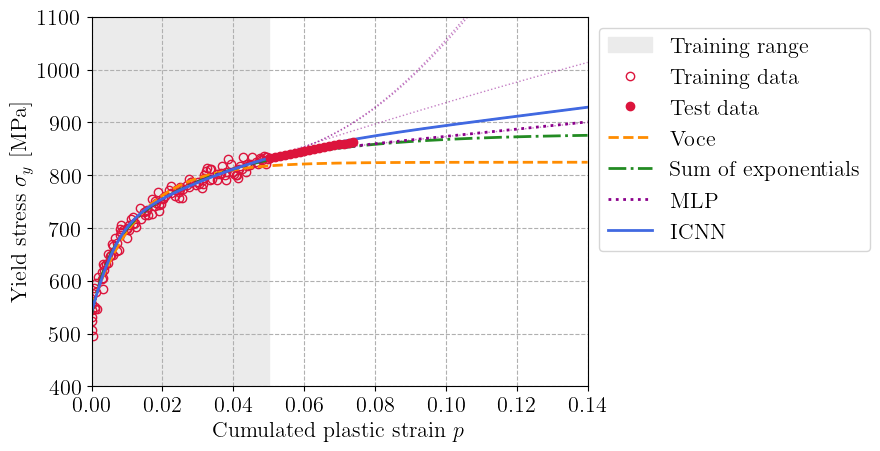

In [6]:
def plot_runs(ax, name, fn):
    """Best run as a thick line, the other runs as thin lines."""
    style = STYLE[name]
    for model, _ in runs[name]:
        if model is not best[name]:
            ax.plot(
                p_plot,
                fn(model),
                color=style["color"],
                ls=style["ls"],
                lw=1.0,
                alpha=0.5,
            )
    ax.plot(p_plot, fn(best[name]), lw=2.0, label=name, **style)


fig, ax = plt.subplots()
ax.axvspan(0.0, p_train_max, color="0.92", zorder=0, label="Training range")
ax.plot(p_train, sig_train, "o", mfc="none", color="crimson", label="Training data")
ax.plot(
    p_test[::3],
    sig_test[::3],
    "o",
    color="crimson",
    zorder=3,
    label="Test data",
)
for name in STYLE:
    plot_runs(ax, name, lambda m: jax.vmap(m)(p_plot))
ax.set_xlim(0, p_extrap_max)
ax.set_ylim(400, 1100)
ax.set_xlabel("Cumulated plastic strain $p$")
ax.set_ylabel(r"Yield stress $\sigma_y$ [MPa]")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
for ext in ("pdf", "png"):
    fig.savefig(f"hardening_laws.{ext}", bbox_inches="tight")
plt.show()

The reference hardening modulus is the slope of the reference curve, computed by central finite
differences over a strain interval of 0.004.

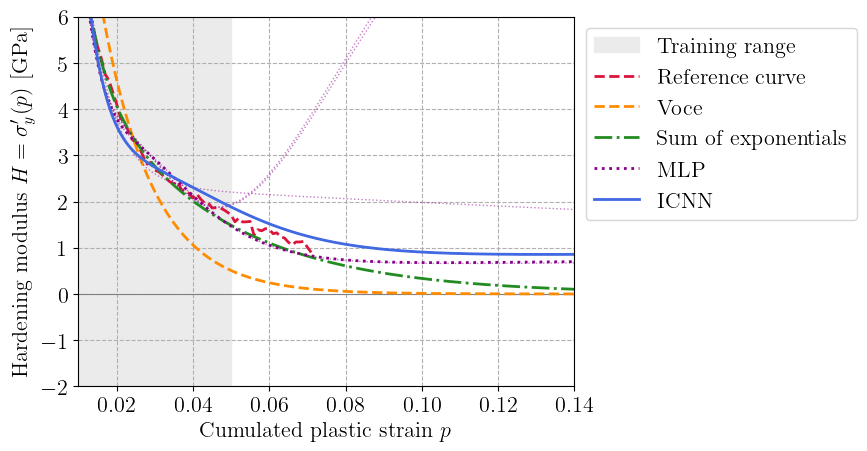

In [7]:
dp = 2e-3
p_mid = np.arange(0.01, p_ref_curve.max() - dp, 1e-3)
H_ref = (
    np.interp(p_mid + dp, p_ref_curve, sig_ref_curve)
    - np.interp(p_mid - dp, p_ref_curve, sig_ref_curve)
) / (2 * dp)

fig, ax = plt.subplots()
ax.axvspan(0.0, p_train_max, color="0.92", zorder=0, label="Training range")
ax.axhline(0.0, color="0.5", lw=0.8)
ax.plot(p_mid, 1e-3 * H_ref, color="crimson", ls="--", lw=2.0, label="Reference curve")
for name in STYLE:
    plot_runs(ax, name, lambda m: 1e-3 * hardening_modulus(m, p_plot))
ax.set_xlim(0.01, p_extrap_max)
ax.set_ylim(-2.0, 6.0)
ax.set_xlabel("Cumulated plastic strain $p$")
ax.set_ylabel(r"Hardening modulus $H = \sigma_y'(p)$ [GPa]")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
for ext in ("pdf", "png"):
    fig.savefig(f"hardening_modulus.{ext}", bbox_inches="tight")
plt.show()

## The calibrated slot inside the three-dimensional elastoplastic model

Each calibrated law (best run) is inserted, unchanged, in the small-strain von Mises model with
isotropic hardening (`vonMisesIsotropicHardening`), with the same isotropic elasticity
($E = 210$ GPa, $\nu = 0.3$); only the `yield_stress` argument differs between the four
materials. The constitutive update is the implicit return mapping obtained by a backward Euler
discretization. Its solution is unique when $\sigma_y$ is non-decreasing, which holds by
construction for the first three implementations but not for the MLP. The models are loaded in
uniaxial tension up to $\varepsilon_{xx} = 0.15$, the lateral stresses being zero. The unknown
lateral strains are obtained at each increment by the mixed-control Newton solver of
`jaxmat.loader`, whose Jacobian is the consistent tangent operator obtained by automatic
differentiation of the constitutive update, including through the neural hardening laws.

Voce                 Newton iterations per increment: max 4
Sum of exponentials  Newton iterations per increment: max 4
MLP                  Newton iterations per increment: max 4
ICNN                 Newton iterations per increment: max 4


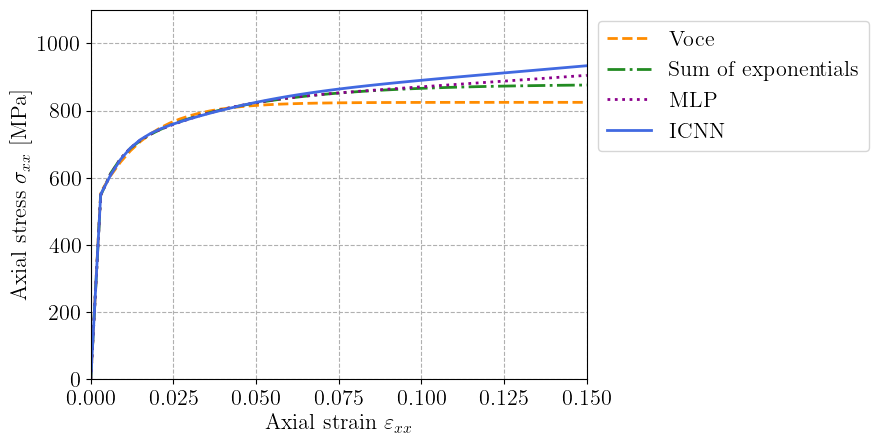

In [8]:
elasticity = jm.LinearElasticIsotropic(E=210e3, nu=0.3)
eps_xx = np.linspace(0.0, 0.15, 51)


def uniaxial_tension(material):
    state = material.init_state(1)
    sig_xx, newton = [0.0], []
    for eps in eps_xx[1:]:
        loading = ImposedLoading(epsxx=eps, sigyy=0.0, sigzz=0.0)
        _, state, stats = global_solve(state.strain, state, loading, material, 0.0)
        sig_xx.append(float(state.stress[0, 0, 0]))
        newton.append(int(stats["num_steps"][0]))
    return np.array(sig_xx), np.array(newton)


responses = {}
for name in STYLE:
    material = jm.vonMisesIsotropicHardening(
        elasticity=elasticity, yield_stress=best[name]
    )
    responses[name] = uniaxial_tension(material)
    print(f"{name:20s} Newton iterations per increment: max {responses[name][1].max()}")

fig, ax = plt.subplots()
for name, style in STYLE.items():
    ax.plot(eps_xx, responses[name][0], lw=2.0, label=name, **style)
ax.set_xlabel(r"Axial strain $\varepsilon_{xx}$")
ax.set_ylabel(r"Axial stress $\sigma_{xx}$ [MPa]")
ax.set_xlim(0, 0.15)
ax.set_ylim(0, 1100)
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
for ext in ("pdf", "png"):
    fig.savefig(f"uniaxial_tension.{ext}", bbox_inches="tight")
plt.show()

## Discussion

The values referred to below are those of the tables printed above. They are reported and
discussed in the accompanying paper (section "Elastoplasticity with substitution of the
isotropic hardening law").

All implementations fit the training data with an error of the order of the added noise, and
differ beyond the training range. The Voce law saturates too early. The $\ell^1$ penalty retains
a few terms of the sum of exponentials, which reduces the test error. The ICNN runs converge to
the same law, with the lowest test error, whereas the MLP runs reach a similar training error but
different laws, with a test error that depends on the initialization.

In extrapolation, the response is set by the structure of each implementation rather than by the
data. The Voce law and the sum of exponentials saturate, their hardening modulus decaying to
zero. The ICNN law is non-decreasing by construction, whatever the weights; here its hardening
modulus remains bounded away from zero over the whole range (column `min H`). The extrapolation
of the MLP depends on the initialization, and nothing in its structure prevents a decreasing
yield stress.

Changing the implementation of the slot requires no other change in the constitutive model: the
same return mapping, the same consistent tangent obtained by automatic differentiation and the
same mixed-control driver are used for the four materials.